# US Hydropower Forecasting — run the full pipeline in Jupyter

This notebook runs the same four steps as the scripts in `src/`, one cell at a time, so you can see what each step does and look at the data in between.

**How to use it:** run the cells in order with Shift+Enter. Steps 1 and 2 download data from EIA and USGS (a few minutes the first time; skipped afterwards if the files already exist). Step 4 fits all the models (about two minutes).

The scripts in `src/` are plain Python files (`.py`). This notebook imports them, so the code you run here is exactly the code in the repository.

In [1]:
import sys, os
from pathlib import Path

# make the src/ folder importable from this notebook
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 140)
print("project folder:", ROOT)

project folder: /home/user/workspace/deploy


## Step 1 — Monthly hydropower generation from EIA-923

Form EIA-923 is the federal survey every U.S. power plant files. The function below downloads one annual zip file per year, opens the "Generation and Fuel" workbook inside it, keeps only conventional hydro (fuel code `WAT`, prime mover `HY`), and reshapes the twelve monthly columns into one row per plant per month.

In [2]:
import download_eia923

out = ROOT / "data/processed/eia923_hydro_monthly.csv"
if out.exists():
    print("already downloaded:", out)
else:
    download_eia923.main(list(range(2010, 2025)))

gen = pd.read_csv(out, parse_dates=["date"])
print(f"{len(gen):,} plant-months, {gen.plant_id.nunique():,} plants, {gen.date.min().date()} to {gen.date.max().date()}")
gen.head()

already downloaded: /home/user/workspace/deploy/data/processed/eia923_hydro_monthly.csv


255,876 plant-months, 1,494 plants, 2010-01-01 to 2024-12-01


,plant_id,plant_name,state,date,net_gen_mwh
0,2,Bankhead Dam,AL,2010-01-01,16374.214
1,2,Bankhead Dam,AL,2010-02-01,17429.489
2,2,Bankhead Dam,AL,2010-03-01,13623.309
3,2,Bankhead Dam,AL,2010-04-01,6562.417
4,2,Bankhead Dam,AL,2010-05-01,9332.267


## Step 2 — Daily streamflow from USGS

Each plant in `src/plants.py` is paired with a USGS river gage upstream of it. This step pulls daily mean discharge (cubic feet per second) from the USGS web service and averages it to monthly.

In [3]:
import download_usgs
from plants import PLANTS

out = ROOT / "data/processed/usgs_monthly_flow.csv"
if out.exists():
    print("already downloaded:", out)
else:
    download_usgs.main()

pd.DataFrame(PLANTS).T[["name", "state", "river", "usgs_site", "gage"]]

already downloaded: /home/user/workspace/deploy/data/processed/usgs_monthly_flow.csv


,name,state,river,usgs_site,gage
2779,Fontana Dam,NC,Little Tennessee River,03503000,"Little Tennessee River at Needmore, NC"
2715,Walters,NC,Pigeon River,03459500,"Pigeon River near Hepco, NC"
54894,Narrows (NC),NC,Yadkin River,02116500,"Yadkin River at Yadkin College, NC"
2714,Tillery,NC,Yadkin / Pee Dee River,02116500,"Yadkin River at Yadkin College, NC"
2722,Cowans Ford,NC,Catawba River,02140991,"Johns River at Arneys Store, NC (Catawba headw..."
3270,Wateree Hydro,SC,Wateree River,02146000,"Catawba River near Rock Hill, SC"
3323,J Strom Thurmond,SC,Savannah River,02192000,"Broad River near Bell, GA (major inflow to Thu..."
2758,Roanoke Rapids,NC,Roanoke River,02077000,"Dan River at Paces, VA"


## Step 3 — Join generation with streamflow and build features

For each plant we line up monthly generation with monthly streamflow at its gage, then add the predictors the models use: generation and flow in the previous 1, 2, 3, and 12 months, rolling averages, and sine/cosine terms for the calendar month.

In [4]:
import build_dataset
df = build_dataset.build()
df[["date", "plant_name", "net_gen_mwh", "flow_mean_cfs", "gen_lag1", "flow_lag1", "gen_lag12"]].dropna().head(8)

wrote /home/user/workspace/deploy/data/processed/model_dataset.csv  (1,440 rows, 8 plants, 2010-01-01 to 2024-12-01)


,date,plant_name,net_gen_mwh,flow_mean_cfs,gen_lag1,flow_lag1,gen_lag12
12,2011-01-01,Fontana Dam,61984.0,758.129032,101516.0,928.290323,117882.0
13,2011-02-01,Fontana Dam,56703.0,853.392857,61984.0,758.129032,122533.0
14,2011-03-01,Fontana Dam,98430.0,1996.064516,56703.0,853.392857,53423.0
15,2011-04-01,Fontana Dam,54862.0,1828.333333,98430.0,1996.064516,7488.0
16,2011-05-01,Fontana Dam,33140.0,948.032258,54862.0,1828.333333,52243.0
17,2011-06-01,Fontana Dam,53294.0,613.466667,33140.0,948.032258,59521.0
18,2011-07-01,Fontana Dam,56329.0,411.483871,53294.0,613.466667,43116.0
19,2011-08-01,Fontana Dam,66723.0,244.451613,56329.0,411.483871,63579.0


### A quick look at one plant

Generation (top) tends to follow river flow (bottom), but not perfectly: the reservoir lets operators store water and shift generation in time. That gap is what makes forecasting interesting.

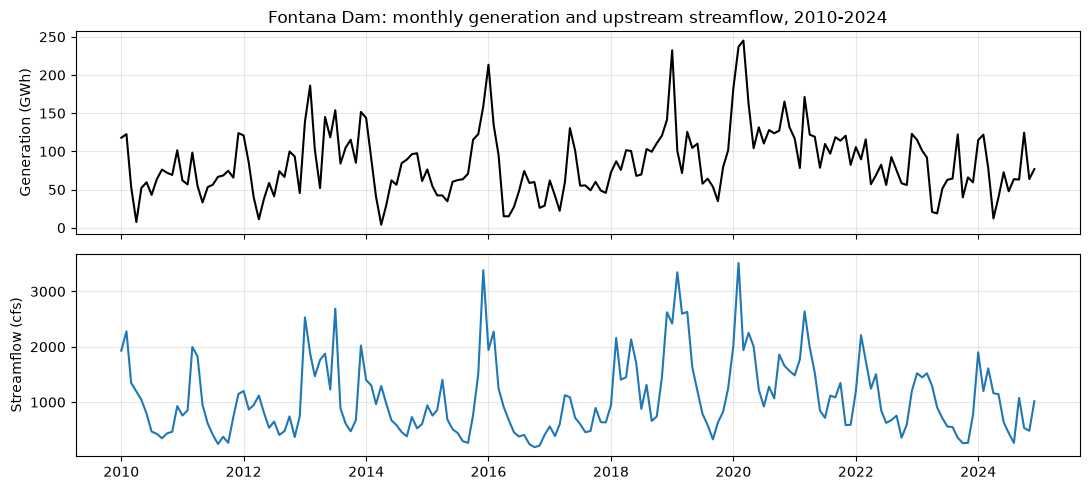

In [5]:
plant = "Fontana Dam"
d = df[df.plant_name == plant]
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ax[0].plot(d.date, d.net_gen_mwh / 1e3, color="black"); ax[0].set_ylabel("Generation (GWh)")
ax[1].plot(d.date, d.flow_mean_cfs, color="tab:blue"); ax[1].set_ylabel("Streamflow (cfs)")
ax[0].set_title(f"{plant}: monthly generation and upstream streamflow, 2010-2024")
for a in ax: a.grid(alpha=.3)
plt.tight_layout()

In [6]:
# how strongly does last month's flow predict this month's generation, plant by plant?
df.groupby("plant_name").apply(lambda g: g["flow_lag1"].corr(g["net_gen_mwh"])).round(2).sort_values(ascending=False).rename("corr(flow_lag1, generation)")

plant_name
J Strom Thurmond    0.72
Narrows (NC)        0.65
Tillery             0.63
Walters             0.61
Wateree Hydro       0.60
Cowans Ford         0.58
Roanoke Rapids      0.57
Fontana Dam         0.48
Name: corr(flow_lag1, generation), dtype: float64

## Step 4 — Fit and compare the forecasting models

Every model is trained on 2011-2019 and asked to forecast one month ahead for each of the 60 months in 2020-2024, using only information available at the end of the previous month (a *rolling origin*). The SARIMA models are refit every month; the tree models are trained once.

The error measure is normalized MAE: mean absolute error divided by the plant's mean generation, so plants of different sizes are comparable. `dry_nMAE` is the same thing computed only on the driest quarter of test months.

In [7]:
import evaluate
evaluate.main()   # about two minutes; writes outputs/

evaluating Fontana Dam


evaluating Walters


evaluating Narrows (NC)


evaluating Tillery


evaluating Cowans Ford


evaluating Wateree Hydro


evaluating J Strom Thurmond


evaluating Roanoke Rapids



Average across plants (lower is better):
                                     nMAE  dry_nMAE
model                                              
Random forest (+ current flow)      0.269     0.310
Gradient boosting (+ current flow)  0.284     0.315
Random forest (lags)                0.315     0.384
Gradient boosting (lags)            0.329     0.397
SARIMAX (+ current flow)            0.342     0.407
SARIMA                              0.352     0.415
Climatology                         0.383     0.460
Seasonal naive                      0.449     0.502


In [8]:
summary = pd.read_csv(ROOT / "outputs/results_summary.csv", index_col=0)
summary

,nMAE,dry_nMAE
model,,
Random forest (+ current flow),0.269,0.310
Gradient boosting (+ current flow),0.284,0.315
Random forest (lags),0.315,0.384
Gradient boosting (lags),0.329,0.397
SARIMAX (+ current flow),0.342,0.407
SARIMA,0.352,0.415
Climatology,0.383,0.460
Seasonal naive,0.449,0.502


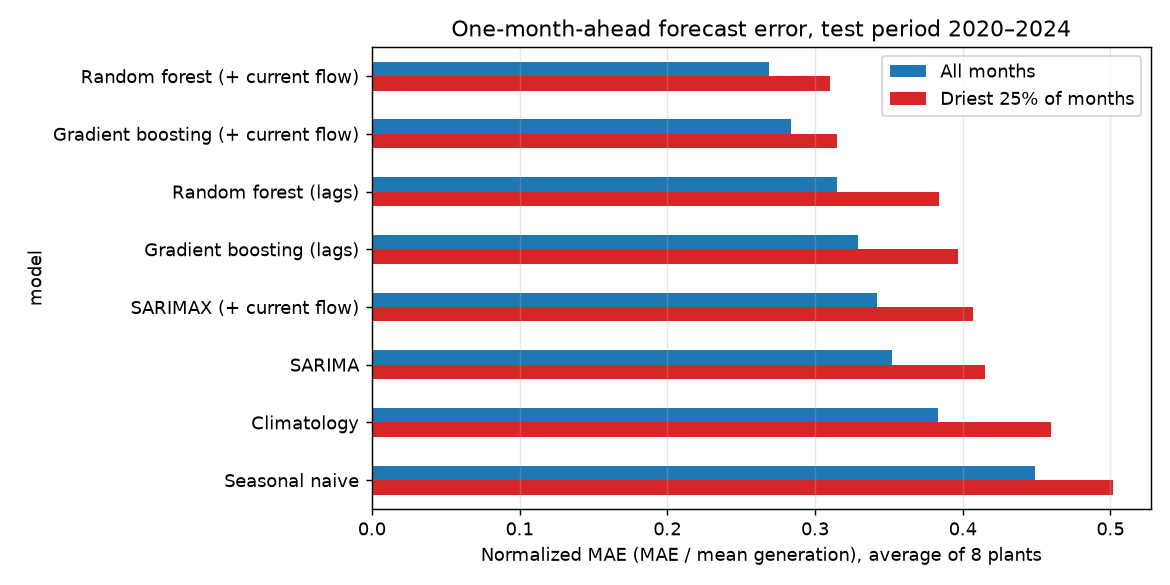

In [9]:
display(Image(filename=str(ROOT / "outputs/model_comparison.png")))

In [10]:
by_plant = pd.read_csv(ROOT / "outputs/results_by_plant.csv")
by_plant.pivot(index="plant", columns="model", values="nMAE").round(2)[
    ["Seasonal naive", "Climatology", "SARIMA", "Random forest (lags)", "Random forest (+ current flow)"]]

model,Seasonal naive,Climatology,SARIMA,Random forest (lags),Random forest (+ current flow)
plant,,,,,
Cowans Ford,0.48,0.39,0.35,0.29,0.26
Fontana Dam,0.41,0.36,0.35,0.29,0.26
J Strom Thurmond,0.35,0.33,0.27,0.25,0.23
Narrows (NC),0.36,0.28,0.33,0.25,0.22
Roanoke Rapids,0.74,0.67,0.49,0.53,0.43
Tillery,0.46,0.35,0.38,0.29,0.24
Walters,0.39,0.35,0.33,0.30,0.24
Wateree Hydro,0.40,0.34,0.32,0.33,0.27


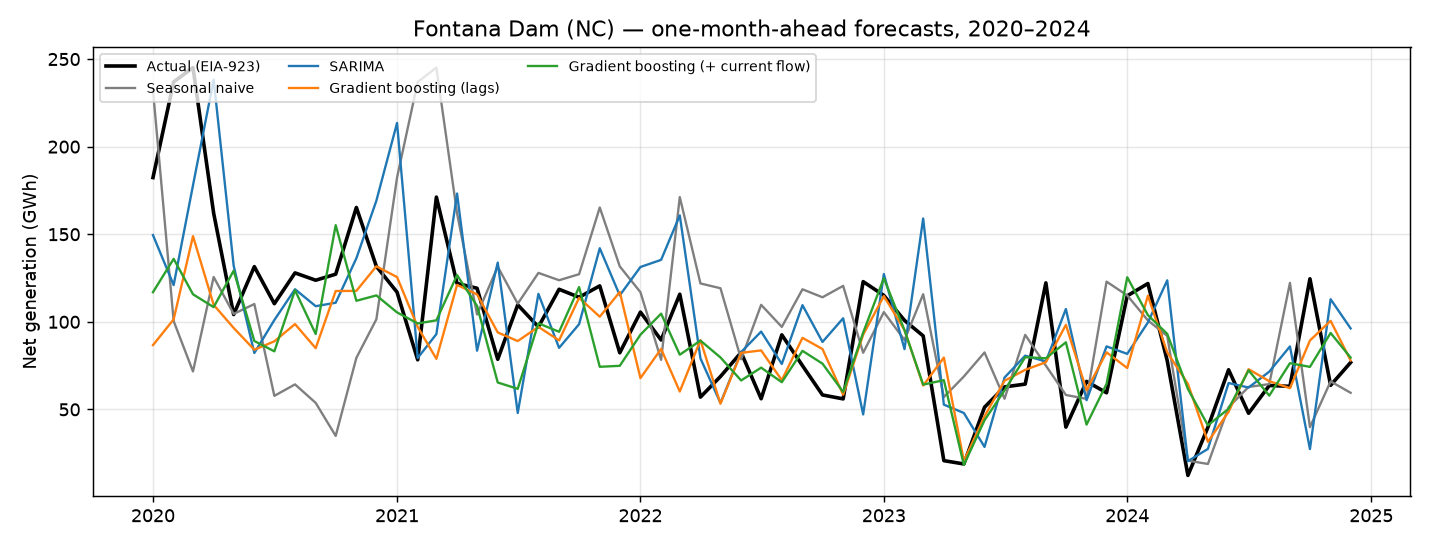

In [11]:
display(Image(filename=str(ROOT / "outputs/forecast_2779_Fontana_Dam.png")))

## What the results say

1. Adding **lagged streamflow** to a tree model beats SARIMA by roughly ten percent and the seasonal-naive forecast by roughly thirty percent.
2. Models that see the **current month's flow** do another fifteen percent better. That is an upper bound, not a real forecast, but it shows how much a good inflow forecast would be worth.
3. **Every model is worse in dry months.** That is the problem operators care about most, and the natural next step for this project.

## Ideas to try next (edit and re-run)

- Add a plant to `src/plants.py` (find its EIA plant code in `data/processed/eia923_hydro_monthly.csv` and a USGS gage on its river).
- Change the SARIMA order in `src/models.py` (`order=(1, 0, 1), seasonal_order=(1, 1, 0, 12)`) and see whether the error moves.
- Try forecasting two or three months ahead instead of one.
- Fit your own ARIMA or SVAR in R on `data/processed/model_dataset.csv` and compare.